# PaySim Fraud Detection: Professional Exploratory Data Analysis

**Project type:** Financial transaction fraud analytics  
**Environment:** Python, pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook, VS Code  
**Dataset:** PaySim synthetic mobile-money transaction records  
**Primary target:** `isFraud`

## Notebook objectives

This notebook builds a reproducible, evidence-based exploratory analysis workflow. It will:

1. Locate and load the PaySim CSV file safely.
2. validate the schema and data quality.
3. quantify target imbalance and compare fraud/non-fraud transactions.
4. analyze transaction types, amounts, time steps, and balance changes.
5. examine the difference between `isFraud` and `isFlaggedFraud`.
6. identify modeling risks, especially target leakage and misleading evaluation.
7. export concise tables and figures for later modeling and reporting.

**Important scope note:** This notebook performs exploratory data analysis (EDA), not production fraud detection. PaySim is simulated data; observed patterns and fraud prevalence must not be interpreted as real-bank estimates.

## 1. Project setup and reproducibility

In this section, we import the libraries used throughout the notebook and configure consistent plotting defaults. Keeping imports and configuration near the top makes the analysis easier to reproduce and debug.

If a package is missing, install it in the active VS Code notebook kernel using the Terminal command documented in the README.

In [1]:
from pathlib import Path
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("default")

sns.set_theme(style="whitegrid", context="notebook")
FIGURE_DIR = Path("outputs") / "figures"
TABLE_DIR = Path("outputs") / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
print("Environment initialized.")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

Environment initialized.
pandas: 3.1.0
NumPy: 2.5.4


## 2. Configure the dataset path

The previous `FileNotFoundError` occurred because the notebook was being executed from a temporary folder while the CSV was stored in your project directory.

Set `DATA_PATH` to the **actual full path** of your file. Based on the project folder shown in VS Code, the likely file is `D:\datasetfruad\paysim.csv`. If the raw file has the long PaySim filename instead, change the value to that exact path.

This cell only defines the path; it does not read the file yet.

In [2]:
DATA_PATH = Path(r"D:\datasetfruad\paysim.csv")

# Alternative if you want to use the original downloaded filename:
# DATA_PATH = Path(r"D:\datasetfruad\PS_20174392719_1491204439457_log.csv")

TARGET = "isFraud"
RULE_FLAG = "isFlaggedFraud"

print("Configured dataset path:", DATA_PATH)
print("File exists:", DATA_PATH.is_file())

Configured dataset path: D:\datasetfruad\paysim.csv
File exists: True


## 3. Find the CSV if the configured path is incorrect

This fallback searches a small number of common locations, including the current working directory and the project directory. It deliberately avoids searching the entire computer, which could be slow and return unrelated files.

If more than one candidate is found, the first candidate is selected. Review the printed path and set `DATA_PATH` explicitly if the selected file is not the intended PaySim dataset.

In [3]:
if not DATA_PATH.is_file():
    search_roots = [
        Path.cwd(),
        Path(r"D:\datasetfruad"),
        Path(r"D:\datasetfruad\PaySim_Fraud_EDA_VSCode_Package"),
    ]
    candidate_names = [
        "paysim.csv",
        "PS_20174392719_1491204439457_log.csv",
        "Fraud.csv",
    ]
    candidates = []
    for root in search_roots:
        if root.exists():
            for filename in candidate_names:
                candidate = root / filename
                if candidate.is_file() and candidate not in candidates:
                    candidates.append(candidate)

    if candidates:
        DATA_PATH = candidates[0]
        print("Using discovered file:", DATA_PATH)
        if len(candidates) > 1:
            print("Other candidates:")
            for candidate in candidates[1:]:
                print(" -", candidate)
    else:
        raise FileNotFoundError(
            "PaySim CSV was not found. Set DATA_PATH in Section 2 to the exact "
            "full path shown in the VS Code Explorer."
        )

assert DATA_PATH.is_file(), f"Dataset file does not exist: {DATA_PATH}"

## 4. Load the dataset

PaySim can contain millions of rows. We use `low_memory=False` to make pandas infer column types more consistently across chunks. Loading the full dataset requires sufficient RAM; if this fails due to memory pressure, use the optional chunked-inspection approach described in the README before continuing.

Do not silently replace the full dataset with a sample for final prevalence estimates. Samples are useful for plotting, but the full dataset is preferred for counts and rates.

In [4]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Loaded file: {DATA_PATH}")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())

Loaded file: D:\datasetfruad\paysim.csv
Rows: 1,048,575
Columns: 11


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


## 5. Validate the expected PaySim schema

The original PaySim dataset commonly contains transaction timing/type, origin and destination identifiers, amounts, balances before and after a transaction, and the labels `isFraud` and `isFlaggedFraud`.

This cell reports missing expected columns rather than assuming that every file is the raw version. A processed file may have renamed or removed columns, and that should be resolved before interpreting results.

In [5]:
expected_columns = [
    "step", "type", "amount", "nameOrig", "oldbalanceOrg",
    "newbalanceOrig", "nameDest", "oldbalanceDest",
    "newbalanceDest", "isFraud", "isFlaggedFraud"
]
missing_columns = [column for column in expected_columns if column not in df.columns]

print("Expected columns:", len(expected_columns))
print("Missing expected columns:", missing_columns if missing_columns else "None")
print("\nActual columns:")
print(df.columns.tolist())

if TARGET not in df.columns:
    raise KeyError(
        f"Target column '{TARGET}' is missing. Check whether DATA_PATH points "
        "to the raw PaySim CSV."
    )

Expected columns: 11
Missing expected columns: None

Actual columns:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


## 6. Inspect data types and memory usage

Data types influence memory consumption, valid operations, and model preparation. This report identifies numeric, categorical, and potentially unexpected object columns.

We inspect memory usage before changing data types. Do not convert identifiers to numbers merely because they contain digits: origin and destination IDs are identifiers, not quantities.

In [6]:
schema_report = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null_count": df.notna().sum(),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(4),
    "n_unique": df.nunique(dropna=True),
})
display(schema_report.sort_values(["missing_percent", "n_unique"], ascending=[False, False]))
print(f"Memory usage: {df.memory_usage(deep=True).sum() / (1024**2):,.2f} MiB")

,dtype,non_null_count,missing_count,missing_percent,n_unique
nameOrig,str,1048575,0,0.0000,1048317
amount,float64,1048575,0,0.0000,1009606
oldbalanceDest,float64,1048575,0,0.0000,590110
nameDest,str,1048575,0,0.0000,449635
newbalanceOrig,float64,1048575,0,0.0000,440792
newbalanceDest,float64,1048575,0,0.0000,437054
oldbalanceOrg,float64,1048575,0,0.0000,391033
step,int64,1048575,0,0.0000,95
type,str,1048575,0,0.0000,5
isFraud,int64,1048575,0,0.0000,2


Memory usage: 239.39 MiB


## 7. Review representative records and summary statistics

`head`, `sample`, and `describe` answer different questions: the first rows show file structure, a random sample reveals typical record shapes, and descriptive statistics summarize numeric distributions.

The sample is used only for inspection. It is not used to calculate the headline fraud rate.

In [7]:
display(df.head(10))
display(df.sample(n=min(10, len(df)), random_state=RANDOM_STATE))
display(df.describe(include="all").T)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0
5,1,PAYMENT,"7,817.7100",C90045638,"53,860.0000","46,042.2900",M573487274,0.0000,0.0000,0,0
6,1,PAYMENT,"7,107.7700",C154988899,"183,195.0000","176,087.2300",M408069119,0.0000,0.0000,0,0
7,1,PAYMENT,"7,861.6400",C1912850431,"176,087.2300","168,225.5900",M633326333,0.0000,0.0000,0,0
8,1,PAYMENT,"4,024.3600",C1265012928,"2,671.0000",0.0000,M1176932104,0.0000,0.0000,0,0
9,1,DEBIT,"5,337.7700",C712410124,"41,720.0000","36,382.2300",C195600860,"41,898.0000","40,348.7900",0,0


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
781974,39,TRANSFER,"574,748.8500",C2141567696,"106,088.0000",0.0000,C883779624,0.0000,"574,748.8500",0,0
937737,43,CASH_IN,"21,118.8400",C696392496,"10,500,000.0000","10,500,000.0000",C1021427324,"2,689,219.9400","2,668,101.1000",0,0
907828,43,CASH_IN,"26,551.7800",C243566485,"20,562.9300","47,114.7100",C1585728667,0.0000,0.0000,0,0
784628,39,PAYMENT,"7,819.0900",C662848077,0.0000,0.0000,M1063211872,0.0000,0.0000,0,0
662460,36,CASH_OUT,"312,914.2100",C2100965538,0.0000,0.0000,C1140936910,"1,310,916.6800","1,623,830.8800",0,0
280139,15,PAYMENT,"2,749.5100",C852772114,"24,543.0000","21,793.4900",M1607889410,0.0000,0.0000,0,0
355572,17,CASH_IN,"208,788.9500",C195088967,"129,823.0000","338,611.9500",C476548973,"39,803.5700",0.0000,0,0
749979,38,PAYMENT,"3,407.8200",C1587889934,"2,965.0000",0.0000,M1983818863,0.0000,0.0000,0,0
374753,17,CASH_OUT,"398,092.2700",C1137502794,508.0000,0.0000,C474223679,0.0000,"398,092.2700",0,0
17327,8,CASH_OUT,"110,892.7400",C1904708954,"25,623.0000",0.0000,C2082673402,0.0000,"218,486.6700",0,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,"1,048,575.0000",NaN,NaN,NaN,26.9662,15.6233,1.0000,15.0000,20.0000,39.0000,95.0000
type,1048575,5,CASH_OUT,373641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,"1,048,575.0000",NaN,NaN,NaN,"158,666.9755","264,940.9304",0.1000,"12,149.0650","76,343.3300","213,761.8900","10,000,000.0000"
nameOrig,1048575,1048317,C918584437,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,"1,048,575.0000",NaN,NaN,NaN,"874,009.5443","2,971,750.5601",0.0000,0.0000,"16,002.0000","136,642.0200","38,900,000.0000"
newbalanceOrig,"1,048,575.0000",NaN,NaN,NaN,"893,808.8980","3,008,271.3334",0.0000,0.0000,0.0000,"174,599.9900","38,900,000.0000"
nameDest,1048575,449635,C985934102,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,"1,048,575.0000",NaN,NaN,NaN,"978,160.0493","2,296,780.3925",0.0000,0.0000,"126,377.2100","915,923.4750","42,100,000.0000"
newbalanceDest,"1,048,575.0000",NaN,NaN,NaN,"1,114,197.9685","2,416,593.1230",0.0000,0.0000,"218,260.3600","1,149,807.5100","42,200,000.0000"
isFraud,"1,048,575.0000",NaN,NaN,NaN,0.0011,0.0330,0.0000,0.0000,0.0000,0.0000,1.0000


## 8. Check missing values and duplicate records

Missing values may be meaningful in some datasets, while exact duplicate rows may indicate repeated records or valid repeated-looking transactions. We report both and do not delete rows automatically.

For financial transaction data, a duplicate-looking row should be investigated using transaction context and identifiers before removal.

In [8]:
missing_report = (
    df.isna().sum()
      .rename("missing_count")
      .to_frame()
      .assign(missing_percent=lambda x: x["missing_count"] / len(df) * 100)
      .sort_values("missing_count", ascending=False)
)
display(missing_report[missing_report["missing_count"] > 0])

duplicate_rows = int(df.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_rows:,} ({duplicate_rows / max(len(df), 1):.4%})")

,missing_count,missing_percent


Exact duplicate rows: 0 (0.0000%)


## 9. Validate the target labels

The target `isFraud` indicates the simulated fraud label. Before computing metrics, inspect its unique values and counts. The target is expected to be binary, usually 0 for non-fraud and 1 for fraud.

This validation prevents a string-coded or unexpected target from being silently misinterpreted.

In [9]:
print("Target dtype:", df[TARGET].dtype)
print("Target values:", sorted(df[TARGET].dropna().unique().tolist(), key=str))
display(df[TARGET].value_counts(dropna=False).rename_axis(TARGET).to_frame("count"))

target_values = set(df[TARGET].dropna().unique().tolist())
if not target_values.issubset({0, 1, False, True}):
    print("WARNING: Target values are not strictly binary 0/1. Investigate before modeling.")

Target dtype: int64
Target values: [0, 1]


,count
isFraud,
0,1047433
1,1142


## 10. Quantify class imbalance

Fraud is usually a rare positive class. Report both counts and percentages: a high overall accuracy can be misleading when the majority class dominates.

The variables `fraud_count`, `nonfraud_count`, and `fraud_rate` are explicitly defined here and will also be recalculated inside the evidence summary section. This avoids the earlier `NameError` when a cell is run out of order.

,class,count,percent_of_binary_labels
0,Non-Fraud,1047433,99.8911
1,Fraud,1142,0.1089


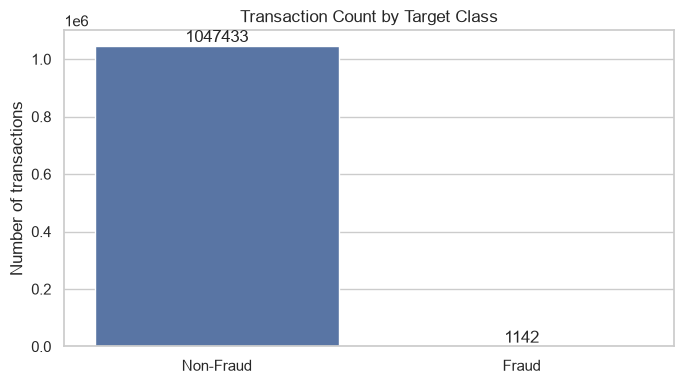

Fraud rows: 1,142 / 1,048,575 (0.10891%)
Interpretation: this is the prevalence in a synthetic dataset, not a real bank's fraud rate.


In [10]:
fraud_count = int(df[TARGET].eq(1).sum())
nonfraud_count = int(df[TARGET].eq(0).sum())
labelled_count = int(df[TARGET].isin([0, 1]).sum())
fraud_rate = fraud_count / labelled_count if labelled_count else np.nan
nonfraud_rate = nonfraud_count / labelled_count if labelled_count else np.nan

class_summary = pd.DataFrame({
    "class": ["Non-Fraud", "Fraud"],
    "count": [nonfraud_count, fraud_count],
    "percent_of_binary_labels": [nonfraud_rate * 100, fraud_rate * 100],
})
display(class_summary)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=class_summary, x="class", y="count", ax=ax)
ax.set_title("Transaction Count by Target Class")
ax.set_xlabel("")
ax.set_ylabel("Number of transactions")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"Fraud rows: {fraud_count:,} / {labelled_count:,} ({fraud_rate:.5%})")
print("Interpretation: this is the prevalence in a synthetic dataset, not a real bank's fraud rate.")

## 11. Compare amount distributions by target

Transaction amounts are often highly skewed. A histogram with a limited plotting sample makes the shape easier to inspect without drawing millions of points. The descriptive table is calculated from all rows.

The plotting sample is for visualization only; it must not be used as the source for the overall fraud rate.

,count,mean,median,std,min,max
isFraud,,,,,,
0,1047433,"157,539.6628","76,214.9700","254,188.2853",0.1000,"6,419,835.2700"
1,1142,"1,192,628.9321","353,179.4500","2,030,598.9638",119.0000,"10,000,000.0000"


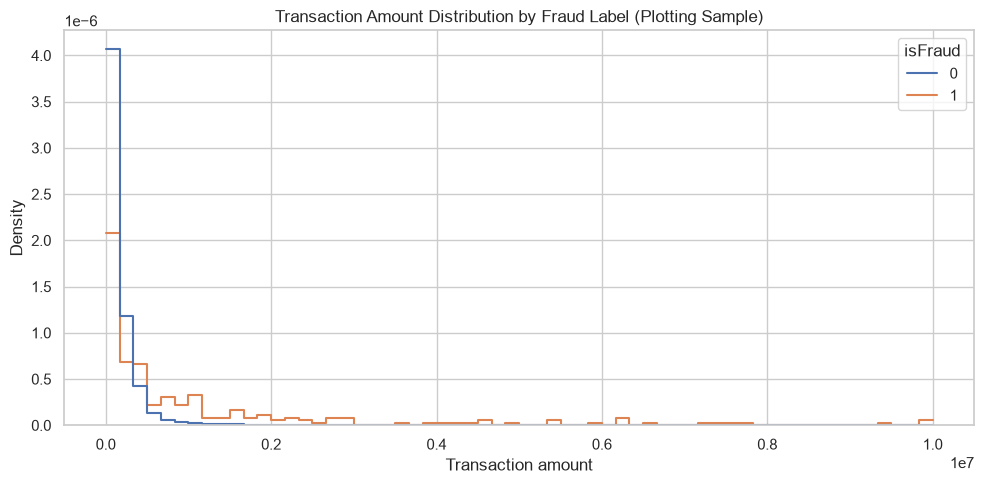

In [11]:
if "amount" in df.columns:
    amount_summary = df.groupby(TARGET, observed=False)["amount"].agg(
        ["count", "mean", "median", "std", "min", "max"]
    )
    display(amount_summary)

    plot_df = df[[TARGET, "amount"]].dropna()
    if len(plot_df) > 200_000:
        plot_df = plot_df.sample(200_000, random_state=RANDOM_STATE)

    fig, ax = plt.subplots(figsize=(10, 5))
    sns.histplot(
        data=plot_df, x="amount", hue=TARGET,
        bins=60, stat="density", common_norm=False,
        element="step", fill=False, ax=ax
    )
    ax.set_title("Transaction Amount Distribution by Fraud Label (Plotting Sample)")
    ax.set_xlabel("Transaction amount")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "amount_distribution_by_target.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("The amount column is not available in this file.")

## 12. Inspect transaction types

Transaction type can be associated with different fraud patterns. We compare raw transaction counts by type and calculate the fraud rate within each type.

A fraud rate is a proportion within a group; it is not the same as the number of fraudulent transactions. Always read the group size alongside the rate, especially for small groups.

,transaction_count
type,
CASH_OUT,373641
PAYMENT,353873
CASH_IN,227130
TRANSFER,86753
DEBIT,7178


,transaction_count,fraud_count,fraud_rate,fraud_rate_percent
type,,,,
TRANSFER,86753,564,0.0065,0.6501
CASH_OUT,373641,578,0.0015,0.1547
CASH_IN,227130,0,0.0000,0.0000
DEBIT,7178,0,0.0000,0.0000
PAYMENT,353873,0,0.0000,0.0000


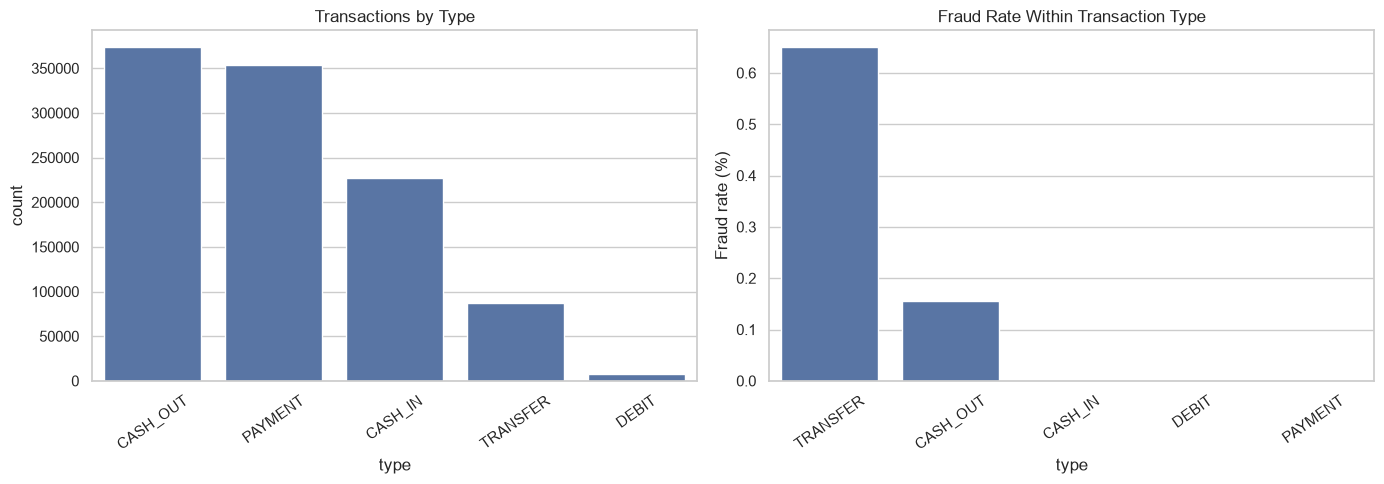

In [12]:
if "type" in df.columns:
    type_counts = df["type"].value_counts(dropna=False).rename("transaction_count").to_frame()
    display(type_counts)

    type_fraud = (
        df.groupby("type", dropna=False, observed=False)[TARGET]
          .agg(transaction_count="size", fraud_count="sum", fraud_rate="mean")
          .sort_values("fraud_rate", ascending=False)
    )
    type_fraud["fraud_rate_percent"] = type_fraud["fraud_rate"] * 100
    display(type_fraud)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.countplot(data=df, x="type", order=df["type"].value_counts().index, ax=axes[0])
    axes[0].set_title("Transactions by Type")
    axes[0].tick_params(axis="x", rotation=35)

    rate_plot = type_fraud.reset_index()
    sns.barplot(data=rate_plot, x="type", y="fraud_rate_percent", ax=axes[1])
    axes[1].set_title("Fraud Rate Within Transaction Type")
    axes[1].set_ylabel("Fraud rate (%)")
    axes[1].tick_params(axis="x", rotation=35)
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "fraud_by_transaction_type.png", dpi=160, bbox_inches="tight")
    plt.show()

## 13. Examine transaction time steps

The `step` column represents a simulation time index, not a real-world timestamp. We aggregate fraud counts and rates by step to identify variation over the simulated period.

A changing rate can be caused by transaction volume, simulation design, or the fraud-generation process. It should not automatically be interpreted as a real-world temporal trend.

,step,transaction_count,fraud_count,fraud_rate
0,1,2708,16,0.0059
1,2,1014,8,0.0079
2,3,552,4,0.0072
3,4,565,10,0.0177
4,5,665,6,0.0090


,step,transaction_count,fraud_count,fraud_rate
29,30,8,8,1.0000
28,29,4,4,1.0000
27,28,4,4,1.0000
30,31,12,12,1.0000
68,69,20,20,1.0000
69,70,6,6,1.0000
70,71,20,20,1.0000
71,72,14,14,1.0000
72,73,8,8,1.0000
73,74,22,22,1.0000


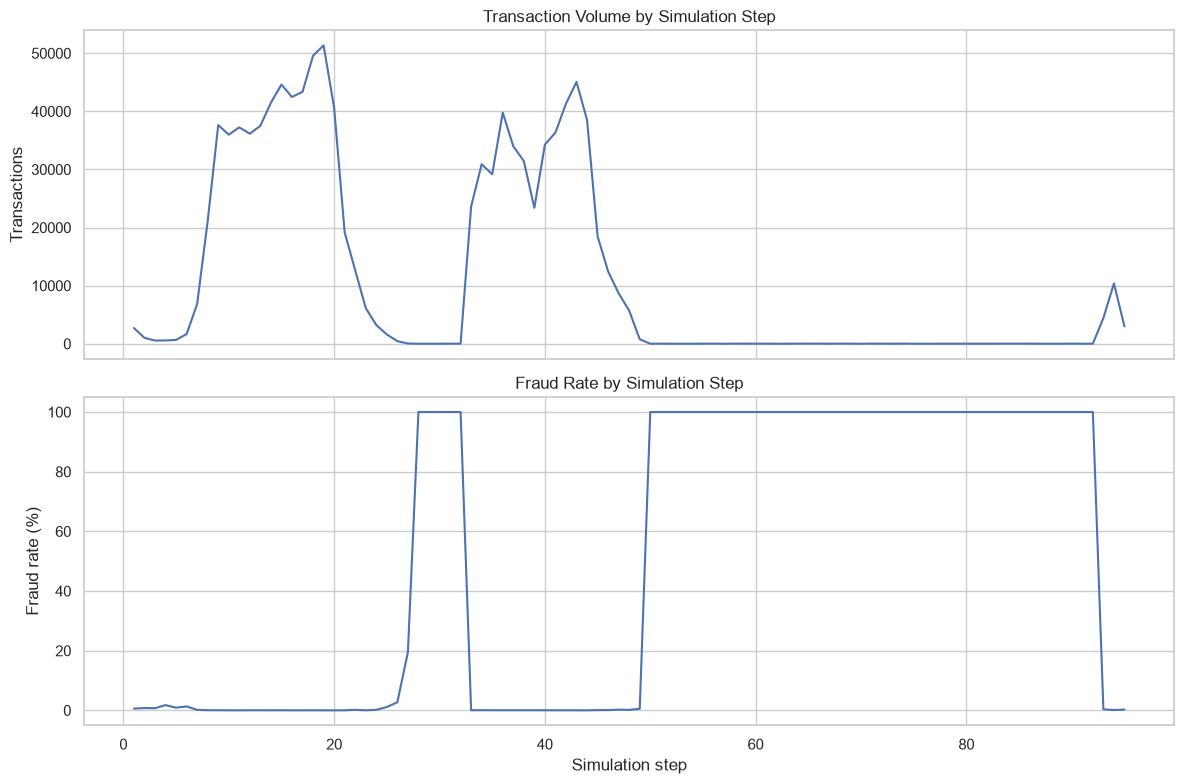

In [13]:
if "step" in df.columns:
    step_summary = df.groupby("step", observed=False)[TARGET].agg(
        transaction_count="size",
        fraud_count="sum",
        fraud_rate="mean"
    ).reset_index()
    display(step_summary.head())
    display(step_summary.sort_values("fraud_rate", ascending=False).head(10))

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    axes[0].plot(step_summary["step"], step_summary["transaction_count"])
    axes[0].set_title("Transaction Volume by Simulation Step")
    axes[0].set_ylabel("Transactions")
    axes[1].plot(step_summary["step"], step_summary["fraud_rate"] * 100)
    axes[1].set_title("Fraud Rate by Simulation Step")
    axes[1].set_ylabel("Fraud rate (%)")
    axes[1].set_xlabel("Simulation step")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "fraud_over_simulation_steps.png", dpi=160, bbox_inches="tight")
    plt.show()

## 14. Investigate balance changes

Origin and destination balances before and after a transaction can help describe simulated transaction behavior. We derive balance differences for exploratory analysis only.

**Modeling caution:** post-transaction balances may be unavailable at the instant a real-time decision must be made. Using them without a clear prediction-time definition can create target leakage or an unrealistic evaluation. Do not assume that a feature is safe merely because it is present in the CSV.

In [14]:
balance_columns = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
available_balance_columns = [column for column in balance_columns if column in df.columns]
display(df[available_balance_columns].describe().T if available_balance_columns else
        pd.DataFrame({"message": ["No expected balance columns were found."]}))

if {"oldbalanceOrg", "newbalanceOrig"}.issubset(df.columns):
    df["origin_balance_change_eda"] = df["newbalanceOrig"] - df["oldbalanceOrg"]
if {"oldbalanceDest", "newbalanceDest"}.issubset(df.columns):
    df["destination_balance_change_eda"] = df["newbalanceDest"] - df["oldbalanceDest"]

derived_columns = [c for c in ["origin_balance_change_eda", "destination_balance_change_eda"] if c in df.columns]
if derived_columns:
    display(df.groupby(TARGET, observed=False)[derived_columns].median())

,count,mean,std,min,25%,50%,75%,max
oldbalanceOrg,"1,048,575.0000","874,009.5443","2,971,750.5601",0.0000,0.0000,"16,002.0000","136,642.0200","38,900,000.0000"
newbalanceOrig,"1,048,575.0000","893,808.8980","3,008,271.3334",0.0000,0.0000,0.0000,"174,599.9900","38,900,000.0000"
oldbalanceDest,"1,048,575.0000","978,160.0493","2,296,780.3925",0.0000,0.0000,"126,377.2100","915,923.4750","42,100,000.0000"
newbalanceDest,"1,048,575.0000","1,114,197.9685","2,416,593.1230",0.0000,0.0000,"218,260.3600","1,149,807.5100","42,200,000.0000"


,origin_balance_change_eda,destination_balance_change_eda
isFraud,,
0,0.0000,0.0000
1,"-348,705.1450","3,733.0350"


## 15. Compare the dataset rule flag with the fraud label

`isFlaggedFraud` is a pre-existing rule-based flag in PaySim. It is not the same as the ground-truth target `isFraud`, and it may flag only a very small subset of transactions.

We compare the flag to the target using a crosstab and calculate precision/recall for the rule flag where both labels are binary. These metrics describe the existing rule in this simulated dataset; they do not describe a trained machine-learning model.

In [15]:
if RULE_FLAG in df.columns:
    rule_values = set(df[RULE_FLAG].dropna().unique().tolist())
    print("isFlaggedFraud values:", sorted(rule_values, key=str))
    display(pd.crosstab(
        df[TARGET], df[RULE_FLAG],
        rownames=["Actual isFraud"], colnames=["Rule isFlaggedFraud"],
        dropna=False
    ))

    binary_rows = df[TARGET].isin([0, 1]) & df[RULE_FLAG].isin([0, 1])
    actual = df.loc[binary_rows, TARGET].astype(int)
    flagged = df.loc[binary_rows, RULE_FLAG].astype(int)
    true_positive = int(((actual == 1) & (flagged == 1)).sum())
    false_positive = int(((actual == 0) & (flagged == 1)).sum())
    false_negative = int(((actual == 1) & (flagged == 0)).sum())
    rule_precision = true_positive / (true_positive + false_positive) if true_positive + false_positive else np.nan
    rule_recall = true_positive / (true_positive + false_negative) if true_positive + false_negative else np.nan

    print(f"Rule-flag precision: {rule_precision:.5f}" if pd.notna(rule_precision) else "Rule-flag precision: undefined (no positive flags)")
    print(f"Rule-flag recall:    {rule_recall:.5f}" if pd.notna(rule_recall) else "Rule-flag recall: undefined (no actual fraud rows)")
else:
    print("isFlaggedFraud is not available; rule-flag evaluation was skipped.")

isFlaggedFraud values: [0]


Rule isFlaggedFraud,0
Actual isFraud,
0,1047433
1,1142


Rule-flag precision: undefined (no positive flags)
Rule-flag recall:    0.00000


## 16. Check numeric correlations carefully

Correlation is a descriptive statistic, not proof of causation. A correlation matrix containing the target and post-transaction balance fields can reveal patterns, but it may also highlight variables that would be unavailable at prediction time.

We include numeric columns only and plot a manageable subset of features with the strongest absolute correlation to the target. Treat this as a diagnostic view, not an automatic feature-selection procedure.

,correlation_with_isFraud
origin_balance_change_eda,-0.2935
amount,0.1289
step,0.0450
destination_balance_change_eda,0.0320
newbalanceOrig,-0.0094
oldbalanceDest,-0.0076
oldbalanceOrg,0.0038
newbalanceDest,-0.0005


d:\datasetfruad\.venv\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


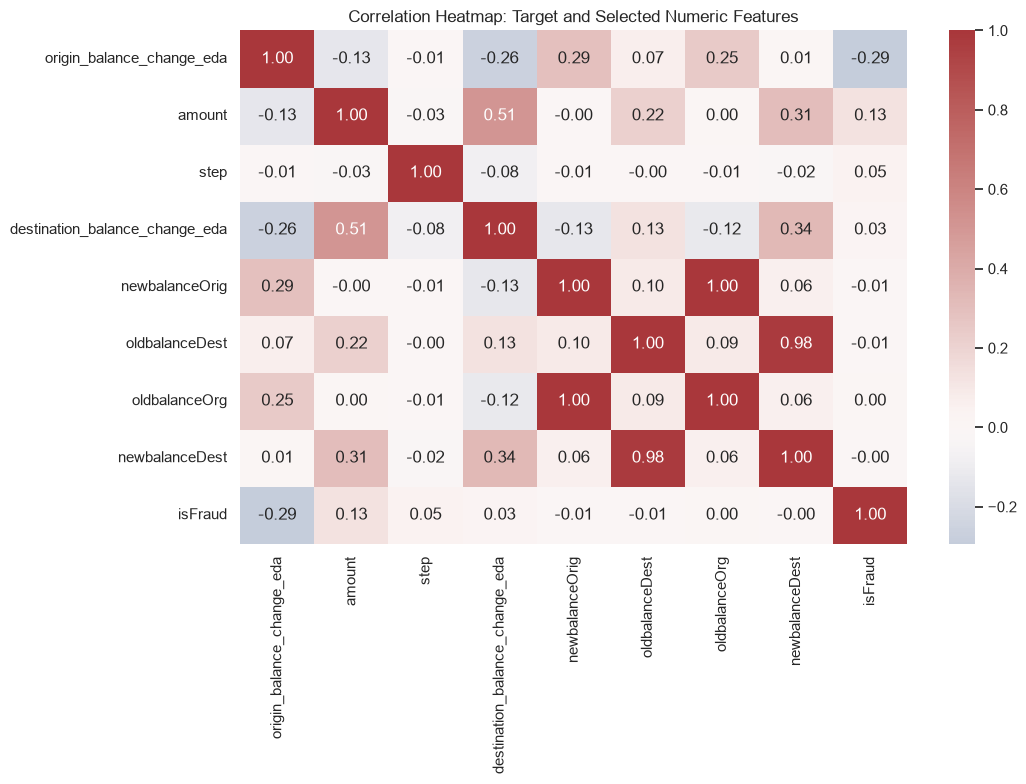

In [16]:
numeric_df = df.select_dtypes(include=[np.number])
if TARGET in numeric_df.columns and numeric_df.shape[1] > 1:
    target_corr = numeric_df.corr(numeric_only=True)[TARGET].drop(TARGET).dropna()
    top_corr_columns = target_corr.abs().sort_values(ascending=False).head(15).index.tolist()
    corr_columns = top_corr_columns + [TARGET]
    corr_matrix = numeric_df[corr_columns].corr(numeric_only=True)

    display(target_corr.loc[top_corr_columns].sort_values(key=lambda s: s.abs(), ascending=False).to_frame("correlation_with_isFraud"))

    fig, ax = plt.subplots(figsize=(11, 8))
    sns.heatmap(corr_matrix, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
    ax.set_title("Correlation Heatmap: Target and Selected Numeric Features")
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / "selected_numeric_correlations.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Not enough numeric columns are available for correlation analysis.")

## 17. Audit possible data leakage and prediction-time availability

A valid fraud model must use only information available when the model is expected to make its decision. The following table categorizes common PaySim fields for investigation; it does not claim that one feature policy fits every deployment.

Before modeling, write down the prediction moment (for example, before authorization) and verify whether each candidate field would exist at that moment.

In [17]:
leakage_audit = pd.DataFrame([
    {"feature": "isFraud", "role": "Ground-truth target", "available_at_decision": "No; target only", "action": "Never include in X"},
    {"feature": "isFlaggedFraud", "role": "Existing rule output", "available_at_decision": "Depends on rule timing", "action": "Exclude from primary model initially; benchmark separately"},
    {"feature": "newbalanceOrig", "role": "Post-transaction origin balance", "available_at_decision": "Potentially after transaction", "action": "Exclude from real-time model unless availability is proven"},
    {"feature": "newbalanceDest", "role": "Post-transaction destination balance", "available_at_decision": "Potentially after transaction", "action": "Exclude from real-time model unless availability is proven"},
    {"feature": "oldbalanceOrg", "role": "Pre-transaction origin balance", "available_at_decision": "Potentially available before transaction", "action": "Verify semantics and availability"},
    {"feature": "oldbalanceDest", "role": "Pre-transaction destination balance", "available_at_decision": "Potentially available before transaction", "action": "Verify semantics and availability"},
    {"feature": "amount", "role": "Transaction amount", "available_at_decision": "Usually before authorization", "action": "Candidate after domain validation"},
    {"feature": "type", "role": "Transaction type", "available_at_decision": "Usually before authorization", "action": "Candidate after encoding"},
    {"feature": "nameOrig/nameDest", "role": "Entity identifiers", "available_at_decision": "Often available", "action": "Avoid naive high-cardinality encoding; consider history-based features"},
])
display(leakage_audit)
leakage_audit.to_csv(TABLE_DIR / "feature_availability_audit.csv", index=False)

,feature,role,available_at_decision,action
0,isFraud,Ground-truth target,No; target only,Never include in X
1,isFlaggedFraud,Existing rule output,Depends on rule timing,Exclude from primary model initially; benchmar...
2,newbalanceOrig,Post-transaction origin balance,Potentially after transaction,Exclude from real-time model unless availabili...
3,newbalanceDest,Post-transaction destination balance,Potentially after transaction,Exclude from real-time model unless availabili...
4,oldbalanceOrg,Pre-transaction origin balance,Potentially available before transaction,Verify semantics and availability
5,oldbalanceDest,Pre-transaction destination balance,Potentially available before transaction,Verify semantics and availability
6,amount,Transaction amount,Usually before authorization,Candidate after domain validation
7,type,Transaction type,Usually before authorization,Candidate after encoding
8,nameOrig/nameDest,Entity identifiers,Often available,Avoid naive high-cardinality encoding; conside...


## 18. Build a compact evidence summary

This section summarizes the most important EDA findings without relying on variables created in earlier cells. The fraud count and fraud rate are recalculated directly from `df`, preventing the `NameError: fraud_count is not defined` issue if this cell is run after a kernel restart.

The summary is a set of observed facts and recommended next actions, not a claim that a model has already been trained.

In [18]:
# Recalculate all core statistics locally so this cell is robust to execution order.
summary_fraud_count = int(df[TARGET].eq(1).sum())
summary_nonfraud_count = int(df[TARGET].eq(0).sum())
summary_labelled_count = int(df[TARGET].isin([0, 1]).sum())
summary_fraud_rate = (
    summary_fraud_count / summary_labelled_count if summary_labelled_count else np.nan
)

evidence_rows = [
    {
        "question": "How imbalanced is the target?",
        "observed_evidence": (
            f"{summary_fraud_count:,} Fraud rows out of {summary_labelled_count:,} "
            f"binary-labeled rows ({summary_fraud_rate:.5%})."
        ),
        "interpretation": "Fraud is a rare positive class in this simulated dataset.",
        "limitation": "This is PaySim simulation prevalence, not a real bank's fraud rate.",
        "next_action": "Use precision, recall, PR-AUC, and a confusion matrix during later model evaluation."
    }
]

if RULE_FLAG in df.columns:
    flagged_count = int(df[RULE_FLAG].eq(1).sum())
    evidence_rows.append({
        "question": "How often does the existing rule flag transactions?",
        "observed_evidence": f"{flagged_count:,} rows have isFlaggedFraud = 1.",
        "interpretation": "The rule flag is distinct from the isFraud target.",
        "limitation": "The simulated rule's behavior may not generalize to real payment systems.",
        "next_action": "Benchmark the rule separately and avoid treating it as the target."
    })

if "type" in df.columns:
    evidence_rows.append({
        "question": "Does fraud rate differ by transaction type?",
        "observed_evidence": "See the transaction-type fraud-rate table in Section 12.",
        "interpretation": "Rates can vary across transaction types.",
        "limitation": "Small group sizes can make rates unstable; simulation patterns may be artificial.",
        "next_action": "Report group sizes with rates and validate patterns on future or external data."
    })

if "newbalanceOrig" in df.columns or "newbalanceDest" in df.columns:
    evidence_rows.append({
        "question": "Could post-transaction balances create leakage?",
        "observed_evidence": "Post-transaction balance fields are present in the dataset.",
        "interpretation": "These fields may describe information unavailable at the real-time decision point.",
        "limitation": "Actual availability depends on the intended production workflow.",
        "next_action": "Define prediction time and build a feature whitelist before training."
    })

evidence_summary = pd.DataFrame(evidence_rows)
display(evidence_summary)
evidence_summary.to_csv(TABLE_DIR / "evidence_summary.csv", index=False)

,question,observed_evidence,interpretation,limitation,next_action
0,How imbalanced is the target?,"1,142 Fraud rows out of 1,048,575 binary-label...",Fraud is a rare positive class in this simulat...,"This is PaySim simulation prevalence, not a re...","Use precision, recall, PR-AUC, and a confusion..."
1,How often does the existing rule flag transact...,0 rows have isFlaggedFraud = 1.,The rule flag is distinct from the isFraud tar...,The simulated rule's behavior may not generali...,Benchmark the rule separately and avoid treati...
2,Does fraud rate differ by transaction type?,See the transaction-type fraud-rate table in S...,Rates can vary across transaction types.,Small group sizes can make rates unstable; sim...,Report group sizes with rates and validate pat...
3,Could post-transaction balances create leakage?,Post-transaction balance fields are present in...,These fields may describe information unavaila...,Actual availability depends on the intended pr...,Define prediction time and build a feature whi...


## 19. Export reusable summary tables

This cell exports data-quality and class-distribution reports so they can be reviewed outside the notebook. Exported outputs are written to the project-relative `outputs/tables` directory.

The notebook does not export the full transaction dataset, which would create an unnecessary duplicate of a large file.

In [19]:
schema_report.to_csv(TABLE_DIR / "schema_report.csv", index=True)
missing_report.to_csv(TABLE_DIR / "missing_values_report.csv", index=True)
class_summary.to_csv(TABLE_DIR / "class_distribution.csv", index=False)
if "type" in df.columns:
    type_fraud.to_csv(TABLE_DIR / "fraud_by_transaction_type.csv", index=True)
if "step" in df.columns:
    step_summary.to_csv(TABLE_DIR / "fraud_by_step.csv", index=False)

print("Tables saved to:", TABLE_DIR.resolve())
print("Figures saved to:", FIGURE_DIR.resolve())

Tables saved to: D:\datasetfruad\outputs\tables
Figures saved to: D:\datasetfruad\outputs\figures


## 20. Final EDA conclusions and modeling handoff

Use the evidence collected above to document what is known, what remains uncertain, and what must be decided before training.

### Required decisions before modeling

1. Define the prediction moment and exclude features unavailable at that moment.
2. Use a chronological or otherwise leakage-aware split where appropriate.
3. Keep the test set untouched until final evaluation.
4. Compare a simple baseline with one or more stronger models.
5. Evaluate precision, recall, F1, PR-AUC, and the confusion matrix; do not rely on accuracy alone.
6. Choose a decision threshold based on operational costs, not on a metric chosen without context.
7. Document that PaySim is synthetic and requires external validation before any real-world use.

This notebook completes EDA. Model training, threshold selection, SQL Server integration, dashboarding, and network-security demonstrations should be developed as separate, testable project stages.

In [20]:
print("EDA workflow completed.")
print(f"Dataset: {DATA_PATH}")
print(f"Rows analyzed: {len(df):,}")
print(f"Columns analyzed: {df.shape[1]:,}")
print(f"Fraud count: {int(df[TARGET].eq(1).sum()):,}")
print(f"Fraud rate: {df[TARGET].eq(1).mean():.5%}")
print(f"Output directory: {(Path.cwd() / 'outputs').resolve()}")

EDA workflow completed.
Dataset: D:\datasetfruad\paysim.csv
Rows analyzed: 1,048,575
Columns analyzed: 13
Fraud count: 1,142
Fraud rate: 0.10891%
Output directory: D:\datasetfruad\outputs
